In [1]:
import zipfile
import os

# Create the base dataset directory if it doesn't exist
base_output_dir = "./dataset"
os.makedirs(base_output_dir, exist_ok=True)

# List of zip files and their corresponding subdirectories
zip_targets = {
    "perruche.zip": "perruche",
    "pas_perruche.zip": "pas_perruche"
}

for zip_file, sub_dir in zip_targets.items():
    if os.path.exists(zip_file):
        # Construct the specific output directory for this zip file
        specific_output_dir = os.path.join(base_output_dir, sub_dir)
        os.makedirs(specific_output_dir, exist_ok=True) # Ensure the subdirectory exists

        with zipfile.ZipFile(zip_file, 'r') as zip_ref:
            # Extract all the contents into the specific output directory
            zip_ref.extractall(specific_output_dir)
        print(f"Extracted {zip_file} to {specific_output_dir}")
    else:
        print(f"Warning: {zip_file} not found. Skipping extraction.")

Extracted perruche.zip to ./dataset/perruche
Extracted pas_perruche.zip to ./dataset/pas_perruche


In [2]:
from pathlib import Path
import shutil
from sklearn.model_selection import train_test_split

# Dossiers source
POS_DIR = Path("./dataset/perruche")
NEG_DIR = Path("./dataset/pas_perruche")

# Dossier de sortie
OUT_DIR = Path("./dataset_split")

# Ratios
TRAIN_RATIO = 0.70
VAL_RATIO = 0.15
TEST_RATIO = 0.15

SEED = 42
IMG_EXTS = {".jpg", ".jpeg", ".png", ".webp"}

def get_images(folder):
    return [p for p in folder.iterdir() if p.suffix.lower() in IMG_EXTS]

def split_files(files):
    train, temp = train_test_split(
        files,
        train_size=TRAIN_RATIO,
        random_state=SEED,
        shuffle=True
    )

    val_ratio_adjusted = VAL_RATIO / (VAL_RATIO + TEST_RATIO)

    val, test = train_test_split(
        temp,
        train_size=val_ratio_adjusted,
        random_state=SEED,
        shuffle=True
    )

    return train, val, test

def copy_files(files, split_name, class_name):
    target_dir = OUT_DIR / split_name / class_name
    target_dir.mkdir(parents=True, exist_ok=True)

    for file in files:
        shutil.copy2(file, target_dir / file.name)

classes = {
    "perruche": POS_DIR,
    "pas_perruche": NEG_DIR
}

for class_name, folder in classes.items():
    files = get_images(folder)

    train_files, val_files, test_files = split_files(files)

    copy_files(train_files, "train", class_name)
    copy_files(val_files, "val", class_name)
    copy_files(test_files, "test", class_name)

    print(f"{class_name}:")
    print(f"  train: {len(train_files)}")
    print(f"  val:   {len(val_files)}")
    print(f"  test:  {len(test_files)}")

print("Dataset prêt.")

perruche:
  train: 3695
  val:   792
  test:  793
pas_perruche:
  train: 2100
  val:   450
  test:  450
Dataset prêt.


In [3]:
import tensorflow as tf
from tensorflow.keras import layers, models
from pathlib import Path

# ==========================
# PARAMÈTRES
# ==========================

# Point to the directory created by the data splitting script
DATASET_SPLIT_PATH = "dataset_split"

IMG_HEIGHT = 128
IMG_WIDTH = 128
BATCH_SIZE = 32
SEED = 42

# ==========================
# CHARGEMENT DES DATASETS SPLITTÉS
# ==========================

# Load training dataset
train_dataset = tf.keras.utils.image_dataset_from_directory(
    Path(DATASET_SPLIT_PATH) / "train",
    labels="inferred",
    label_mode="binary",
    image_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE,
    shuffle=True,
    seed=SEED
)

# Load validation dataset
val_dataset = tf.keras.utils.image_dataset_from_directory(
    Path(DATASET_SPLIT_PATH) / "val",
    labels="inferred",
    label_mode="binary",
    image_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE,
    shuffle=False # No need to shuffle validation data
)

# Load test dataset
test_dataset = tf.keras.utils.image_dataset_from_directory(
    Path(DATASET_SPLIT_PATH) / "test",
    labels="inferred",
    label_mode="binary",
    image_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE,
    shuffle=False # No need to shuffle test data
)

# Affichage des classes détectées (assuming all datasets have the same classes)
print("Classes :", train_dataset.class_names)

# ==========================
# OPTIMISATION DES PERFORMANCES
# ==========================

AUTOTUNE = tf.data.AUTOTUNE

train_dataset = train_dataset.cache().prefetch(buffer_size=AUTOTUNE)
val_dataset = val_dataset.cache().prefetch(buffer_size=AUTOTUNE)
test_dataset = test_dataset.cache().prefetch(buffer_size=AUTOTUNE)

# ==========================
# VÉRIFICATION
# ==========================

print("\nDatasets prêts !")
print(f"Train batches : {len(train_dataset)}")
print(f"Validation batches : {len(val_dataset)}")
print(f"Test batches : {len(test_dataset)}")


Found 5795 files belonging to 2 classes.
Found 1242 files belonging to 2 classes.
Found 1243 files belonging to 2 classes.
Classes : ['pas_perruche', 'perruche']

Datasets prêts !
Train batches : 182
Validation batches : 39
Test batches : 39


In [4]:
import tensorflow as tf
from tensorflow.keras import layers, models

IMG_HEIGHT = 128
IMG_WIDTH = 128

model = models.Sequential([
    layers.Input(shape=(IMG_HEIGHT, IMG_WIDTH, 3)),
    layers.Rescaling(1./255),

    layers.Conv2D(32, 3, padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D(),

    layers.Conv2D(64, 3, padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D(),

    layers.Conv2D(128, 3, padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D(),

    layers.Conv2D(192, 3, padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D(),

    layers.Conv2D(256, 3, padding="same", activation="relu"),
    layers.BatchNormalization(),

    layers.GlobalAveragePooling2D(),

    layers.Dense(128, activation="relu"),
    layers.Dropout(0.3),

    layers.Dense(2, activation="softmax")
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0005),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 192)    │       221,376 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 16, 16, 192)    │           768 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 8, 8, 192)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 8, 8, 256)      │       442,624 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 8, 8, 256)      │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 2)              │           258 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 793,090 (3.03 MB)

 Trainable params: 791,746 (3.02 MB)

 Non-trainable params: 1,344 (5.25 KB)

In [5]:
history = model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=20
)

Epoch 1/20
182/182 ━━━━━━━━━━━━━━━━━━━━ 412s 2s/step - accuracy: 0.8697 - loss: 0.3157 - val_accuracy: 0.6377 - val_loss: 0.9694
Epoch 2/20
182/182 ━━━━━━━━━━━━━━━━━━━━ 437s 2s/step - accuracy: 0.9356 - loss: 0.1691 - val_accuracy: 0.6506 - val_loss: 0.8854
Epoch 3/20
182/182 ━━━━━━━━━━━━━━━━━━━━ 455s 2s/step - accuracy: 0.9508 - loss: 0.1369 - val_accuracy: 0.8591 - val_loss: 0.3573
Epoch 4/20
182/182 ━━━━━━━━━━━━━━━━━━━━ 413s 2s/step - accuracy: 0.9551 - loss: 0.1186 - val_accuracy: 0.9388 - val_loss: 0.1783
Epoch 5/20
182/182 ━━━━━━━━━━━━━━━━━━━━ 405s 2s/step - accuracy: 0.9629 - loss: 0.1045 - val_accuracy: 0.9517 - val_loss: 0.1729
Epoch 6/20
182/182 ━━━━━━━━━━━━━━━━━━━━ 415s 2s/step - accuracy: 0.9684 - loss: 0.0922 - val_accuracy: 0.9573 - val_loss: 0.1448
Epoch 7/20
182/182 ━━━━━━━━━━━━━━━━━━━━ 403s 2s/step - accuracy: 0.9682 - loss: 0.0906 - val_accuracy: 0.9179 - val_loss: 0.2122
Epoch 8/20
182/182 ━━━━━━━━━━━━━━━━━━━━ 407s 2s/step - accuracy: 0.9714 - loss: 0.0819 - val_accu

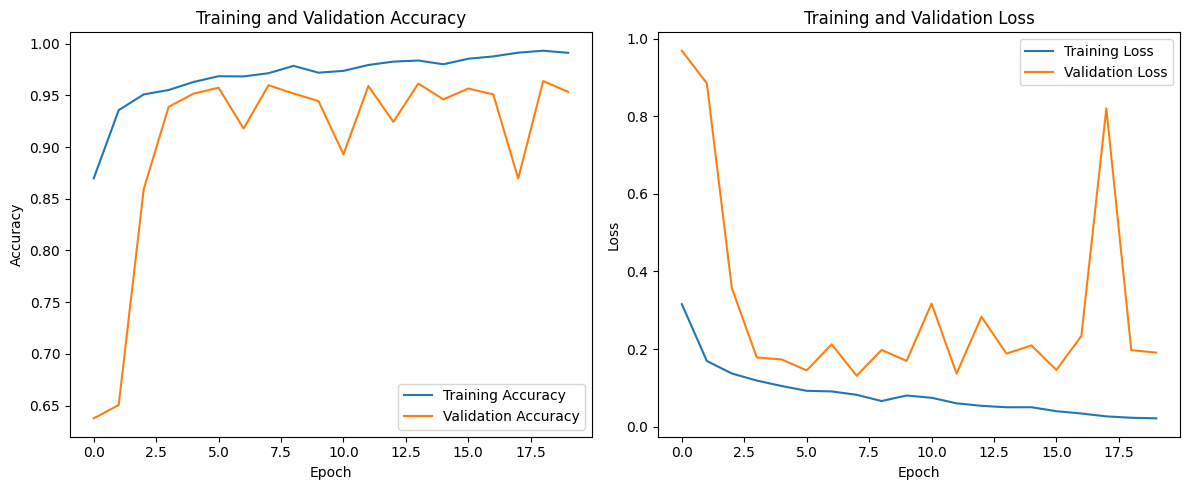

39/39 ━━━━━━━━━━━━━━━━━━━━ 32s 807ms/step - accuracy: 0.9598 - loss: 0.1655
Accuracy test : 0.9598
Loss test : 0.1655


In [7]:
import matplotlib.pyplot as plt

# Plot training history
hist = history.history
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(hist['accuracy'], label='Training Accuracy')
plt.plot(hist['val_accuracy'], label='Validation Accuracy')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(hist['loss'], label='Training Loss')
plt.plot(hist['val_loss'], label='Validation Loss')
plt.title('Training and Validation Loss')

plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()

# Evaluate on test set
loss, accuracy = model.evaluate(test_dataset)

print(f"Accuracy test : {accuracy:.4f}")
print(f"Loss test : {loss:.4f}")


In [8]:
converter = tf.lite.TFLiteConverter.from_keras_model(model)
tflite_model = converter.convert()

with open("my_bird_model_v3.tflite", "wb") as f:
    f.write(tflite_model)

Saved artifact at '/tmp/tmps0fl6isu'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 128, 128, 3), dtype=tf.float32, name='keras_tensor')
Output Type:
  TensorSpec(shape=(None, 2), dtype=tf.float32, name=None)
Captures:
  134429526858000: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134429526860496: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134429526859152: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134429526861072: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134429526858192: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134429526859728: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134429526861264: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134429526861648: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134429526860688: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134429526862032: TensorSpec(shape=(), dtype=tf.resource, name=None)
  13442952685934

In [9]:
from google.colab import files

files.download("my_bird_model_v3.tflite")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>